# Wave: common and individual degree comparisons

The supplied reference statistics contain 50 repetitions for every method and selection strategy.

In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import FuncNorm
from matplotlib.ticker import FuncFormatter, FormatStrFormatter
from IPython.display import display
HERE=Path.cwd()
DATA=HERE/'Data'
FIG=HERE/'Figures'
FIG.mkdir(exist_ok=True)
from PCA_Theta import load_result
METHODS=['random_ols','lhs_ols','theta_ols','pca_theta_ols','qv_theta_ols','qv_pca_theta_ols']
LABELS=['Random-OLS','LHS-OLS',r'$\Theta$-OLS',r'PCA-$\Theta$-OLS',r'$\eta$-$\Theta$-OLS',r'$\eta$-PCA-$\Theta$-OLS']
COLORS=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#17becf']
CONTRAST_POWER=2.0

def shared_norm(densities):
    maximum = float(np.max(densities))
    step = 1. if maximum <= 5. else (5. if maximum <= 30. else 10.)
    upper = max(2., float(np.ceil(maximum / step) * step))
    # c=(rho**2-1)/(rho**2+1): zero density -> -1, uniform -> 0.
    # Scale the positive branch to the common upper limit so uniform is
    # exactly the white midpoint, including figures with a different range.
    upper_contrast = (upper**CONTRAST_POWER - 1.) / (upper**CONTRAST_POWER + 1.)
    def forward(value):
        power = np.power(value, CONTRAST_POWER)
        contrast = (power - 1.) / (power + 1.)
        return np.where(contrast >= 0., contrast / upper_contrast, contrast)
    def inverse(value):
        contrast = np.where(value >= 0., value * upper_contrast, value)
        return np.power((1. + contrast) / (1. - contrast), 1. / CONTRAST_POWER)
    return FuncNorm((forward, inverse), vmin=0., vmax=upper, clip=False)

In [2]:
import numpy as np

EXAMPLE_NAME = "wave"
BOUNDS = [(0.0, 1.0), (0.0, 2.0)]


def evaluate(X):
    X = np.asarray(X, dtype=float)
    x, t = X[:, 0], X[:, 1]
    u1 = np.sin(np.pi * x) * np.cos(2.0 * np.pi * t)
    u2 = np.sin(2.0 * np.pi * x) * np.cos(4.0 * np.pi * t)
    return np.column_stack([
        u1,
        1.03 * u1 + 0.015 * u2,
        0.97 * u1 + 0.05 * u2,
        -0.32 * np.pi * np.sin(np.pi * x) * np.sin(2.0 * np.pi * t),
        0.30 * np.pi * np.cos(np.pi * x) * np.cos(2.0 * np.pi * t),
        0.55 * u2,
    ])


def build_model(args):
    return evaluate, {"n_outputs": 6, "wave_speed": 2.0}

In [3]:
from matplotlib.colors import Normalize
PLOTS=FIG
STATS=np.load(DATA/'results.npz',allow_pickle=False)
BUDGET=STATS['n']
MODES=('common','individual')
DEGREE_TITLES=(r'Common $p$',r'Individual $p_j$')
FMT=FormatStrFormatter('%g')
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],
                     'mathtext.fontset':'stix','font.size':14,'axes.labelsize':14,'axes.titlesize':14,
                     'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14,'legend.frameon':False,
                     'axes.grid':False,'pdf.fonttype':42,'ps.fonttype':42,'axes.linewidth':.8})

def save(fig,stem):
    fig.savefig(PLOTS/(stem+'.pdf'),facecolor='white',dpi=240)
    display(fig); plt.close(fig)

def clean(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(direction='out',length=3)

def legend(fig,y=.005):
    handles=[Line2D([],[],lw=1.9,color=c,label=l) for c,l in zip(COLORS,LABELS)]
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,y),ncol=3,
               handlelength=1.6,columnspacing=1.2,handletextpad=.45,borderaxespad=0)

def draw_curve(ax,mode,key,output=None):
    for m,color in enumerate(COLORS):
        v=STATS[f'{mode}_{m}_{key}']
        degrees=key=='p_selected_outputs'
        if degrees: v=v[:,:,output]
        else:
            assert np.all(v>0)
            v=np.log10(v)
        mean=v.mean(axis=0);sd=v.std(axis=0,ddof=1)
        ax.fill_between(BUDGET,mean-sd,mean+sd,color=color,alpha=.08,linewidth=0)
        if not degrees:
            for bound in (mean-sd,mean+sd):
                ax.plot(BUDGET,bound,color=color,linestyle='--',lw=.50,alpha=.53)
        ax.plot(BUDGET,mean,color=color,lw=1.5)
    clean(ax)
    ax.set_xlim(0,1020)

def degrees():
    fig,ax=plt.subplots(figsize=(6.8,4.5))
    draw_curve(ax,'common','p_selected_outputs',0)
    ax.set(xticks=[0,250,500,750,1000],ylim=(3,26),yticks=[5,10,15,20,25],
           ylabel=r'Selected degree $p$',xlabel='Number of training samples')
    fig.subplots_adjust(left=.12,right=.96,bottom=.30,top=.96)
    legend(fig);save(fig,'wave_common_p_selection')
    fig,axes=plt.subplots(2,3,figsize=(9.0,5.30),sharex=True,sharey=True)
    for j,ax in enumerate(axes.flat):
        draw_curve(ax,'individual','p_selected_outputs',j)
        ax.set(xticks=[0,500,1000],ylim=(3,26),yticks=[5,10,15,20,25])
        ax.text(.94,.085,rf'$Y_{{{j+1}}}$',transform=ax.transAxes,va='bottom',ha='right',
                bbox={'facecolor':'#e3f0f7','edgecolor':'none','pad':2})
    fig.subplots_adjust(left=.10,right=.975,bottom=.265,top=.96,hspace=.23,wspace=.16)
    fig.text(.038,.616,r'Selected degree $p_j$',ha='center',va='center',rotation=90)
    fig.text(.53,.17,'Number of training samples',ha='center',va='center')
    legend(fig);save(fig,'wave_individual_p_selection')

def convergence():
    fig,axes=plt.subplots(2,3,figsize=(9.10,5.65),sharex=True,sharey='col')
    for i,mode in enumerate(MODES):
        for col,(key,title,lo,hi) in enumerate([('nrmse','NRMSE',-5,1),('nmae','NMAE',-6,1),('nmaxae','NMaxAE',-3,2)]):
            ax=axes[i,col];draw_curve(ax,mode,key)
            for m in range(6):
                mean=np.log10(STATS[f'{mode}_{m}_{key}']).mean(0)
                assert np.all((lo<mean)&(mean<hi))
            ax.set(xticks=[0,500,1000],ylim=(lo,hi),yticks=np.arange(lo,hi+1))
            if i==0: ax.set_title(title,pad=5)
            if col==0:
                ax.text(.045,.065,DEGREE_TITLES[i],transform=ax.transAxes,fontsize=12,
                        bbox={'facecolor':'#e3f0f7','edgecolor':'none','pad':2})
    fig.subplots_adjust(left=.105,right=.975,bottom=.242,top=.925,hspace=.24,wspace=.29)
    fig.text(.030,.57,r'$\log_{10}(\varepsilon^{\mathrm{norm}})$',va='center',ha='center',rotation=90)
    fig.text(.53,.165,'Number of training samples',va='center',ha='center')
    legend(fig);save(fig,'wave_normalized_log_convergence')

def analytical_fields():
    x,t=np.meshgrid(np.linspace(0,1,181),np.linspace(0,2,241))
    values=evaluate(np.column_stack([x.ravel(),t.ravel()])).reshape(*x.shape,6)
    maximum=np.abs(values).max()
    fig,axes=plt.subplots(2,3,figsize=(8.6,4.75),sharex=True,sharey=True)
    for j,ax in enumerate(axes.flat):
        im=ax.imshow(values[:,:,j],extent=(0,1,0,2),origin='lower',aspect='auto',
                     cmap='RdBu_r',norm=Normalize(-maximum,maximum),interpolation='bilinear')
        ax.set(xticks=[0,.5,1],yticks=[0,1,2],title=rf'$Y_{{{j+1}}}$')
        ax.xaxis.set_major_formatter(FMT)
    fig.subplots_adjust(left=.095,right=.83,bottom=.16,top=.92,wspace=.15,hspace=.30)
    fig.text(.46,.033,r'$x$',ha='center');fig.text(.038,.54,r'$t$',ha='center',rotation=90)
    cax=fig.add_axes([.858,.235,.022,.57]);bar=fig.colorbar(im,cax=cax,ticks=[-1,-.5,0,.5,1],format=FMT)
    bar.set_label('Response value',labelpad=5)
    save(fig,'wave_analytical_outputs')

def density():
    arrays=np.stack([STATS[f'{mode}_{m}_density'] for mode in MODES for m in range(6)])
    norm=shared_norm(arrays)
    fig,axes=plt.subplots(2,5,figsize=(9.45,4.95),sharex=True,sharey=True)
    names=['Non-adaptive',r'$\Theta$',r'PCA-$\Theta$',r'$\eta$-$\Theta$',r'$\eta$-PCA-$\Theta$']
    for row,mode in enumerate(MODES):
        for col,m in enumerate([row,2,3,4,5]):
            ax=axes[row,col]
            im=ax.imshow(STATS[f'{mode}_{m}_density'].T,extent=(0,1,0,2),origin='lower',
                         norm=norm,cmap='RdBu_r',aspect='auto',interpolation='bilinear')
            ax.set_box_aspect(1)
            ax.set(xticks=[0,.5,1],yticks=[0,1,2])
            ax.xaxis.set_major_formatter(FMT)
            if row==0:ax.set_title(names[col],pad=6,fontsize=14)
            if col==0:
                ax.set_ylabel(r'$t$')
                ax.text(.04,.04,['Random','LHS'][row],transform=ax.transAxes,fontsize=11,
                        bbox={'facecolor':'white','edgecolor':'none','pad':1.3,'alpha':.88})
    fig.subplots_adjust(left=.11,right=.985,bottom=.263,top=.905,hspace=.17,wspace=.15)
    fig.text(.022,.75,DEGREE_TITLES[0],ha='center',va='center',rotation=90)
    fig.text(.022,.418,DEGREE_TITLES[1],ha='center',va='center',rotation=90)
    fig.text(.547,.157,r'$x$',ha='center',va='center')
    cax=fig.add_axes([.315,.089,.46,.026])
    ticks=np.unique([0,.5,1,2,norm.vmax])
    cb=fig.colorbar(im,cax=cax,orientation='horizontal',ticks=ticks,format=FMT)
    cb.minorticks_off();cb.ax.tick_params(pad=2);cb.set_label('Relative density',labelpad=1)
    save(fig,'wave_sampling')

## Analytical outputs

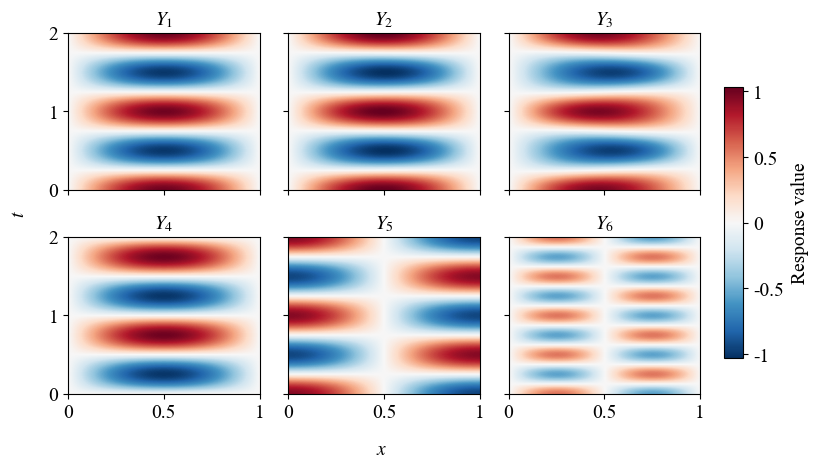

In [4]:
analytical_fields()

## Degree histories

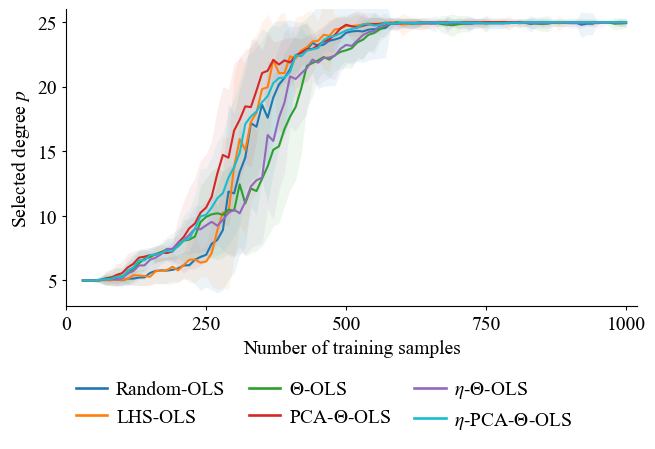

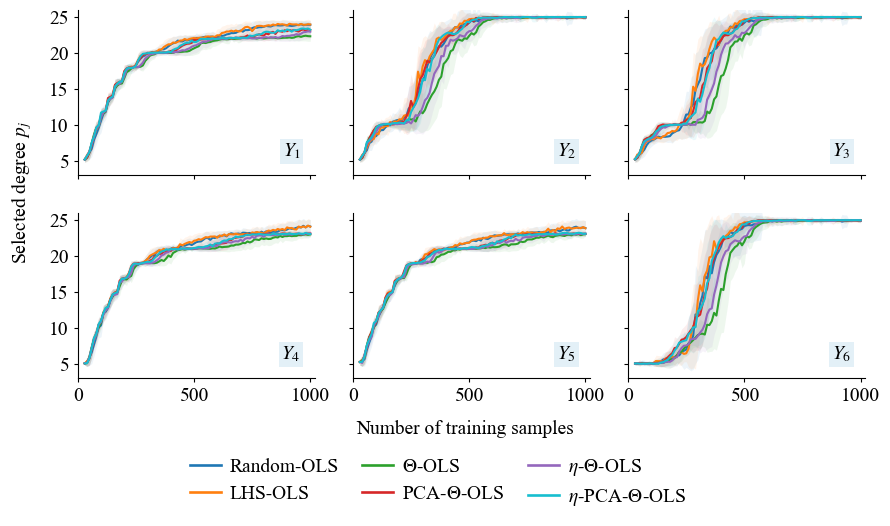

In [5]:
degrees()

## Error curves

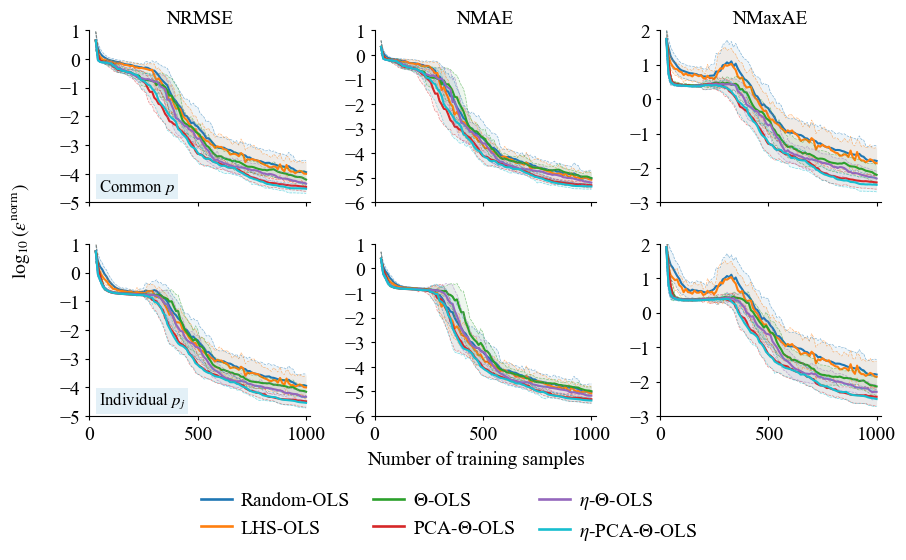

In [6]:
convergence()

## Sampling density

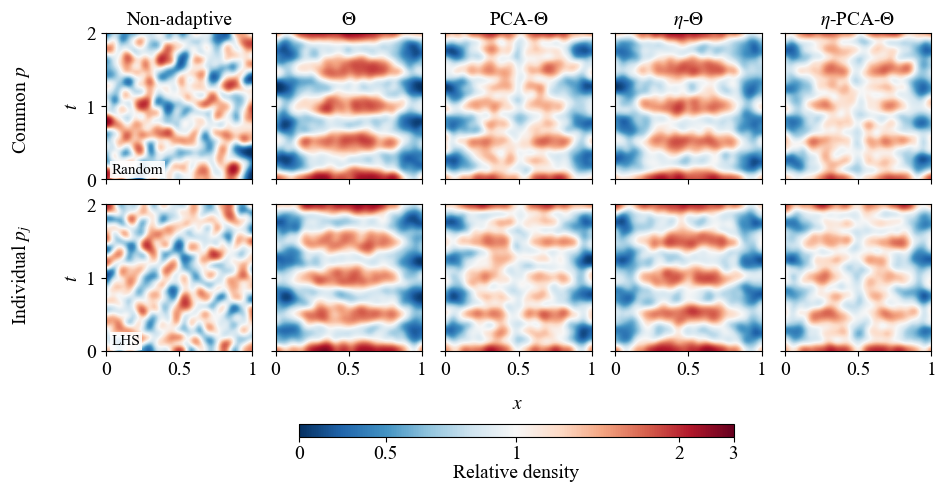

In [7]:
density()

## Effect of eta weighting

In [8]:
with (DATA/'weighting_summary.csv').open() as stream:
    for row in csv.DictReader(stream):
        print(row)

{'example': 'gaussian', 'unweighted_baseline': 'theta_ols', 'mean_eta': '0.20788719194266464', 'fill_distance_reduction_pct': '57.63602144671209', 'nrmse_reduction_pct': '95.28936330728943', 'nmae_reduction_pct': '96.14304264831537', 'nmaxae_reduction_pct': '82.89969779997446'}
{'example': 'gaussian', 'unweighted_baseline': 'pca_theta_ols', 'mean_eta': '0.28073075005527826', 'fill_distance_reduction_pct': '55.342849321034194', 'nrmse_reduction_pct': '89.03302652057761', 'nmae_reduction_pct': '90.57171683263977', 'nmaxae_reduction_pct': '73.8433306678889'}
{'example': 'wave', 'unweighted_baseline': 'theta_ols', 'mean_eta': '0.7318052409302573', 'fill_distance_reduction_pct': '9.27849762501236', 'nrmse_reduction_pct': '28.09730240509818', 'nmae_reduction_pct': '33.282888092595606', 'nmaxae_reduction_pct': '21.769154631697962'}
{'example': 'wave', 'unweighted_baseline': 'pca_theta_ols', 'mean_eta': '0.8318784649463512', 'fill_distance_reduction_pct': '6.73224248342302', 'nrmse_reduction_p